# 01 — Nutrition5k EDA (Adım 6)

Bu notebook baştan sona çalıştırıldığında tüm sayıları ve `results/figures/n5k_*.png` figürlerini yeniden üretir.
Mac'te ~2 dakika sürer (görsel aykırılık taraması ResNet-50 ağırlıklarını bir kez indirir).

**Kararlar ve bulguların özeti en altta (§9).**

In [1]:
import os, sys, hashlib, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from scipy.stats import skew

from src.config import N5K_DIR, CALORIE_BIN_EDGES, RESULTS_DIR
from src.data import (BAD_DISHES, dish_time, make_val_split, read_dish_ingredients,
                      read_dish_metadata, read_split, time_groups)
from src.metrics import calorie_bins, to_bins
from src.plot_style import INK, SERIES, AXIS, apply, savefig, sequential_cmap

apply()
pd.set_option("display.width", 160)
meta, ingr = read_dish_metadata(), read_dish_ingredients()
IMG = N5K_DIR / "realsense_overhead"

def show_dishes(ids, titles, ncols, name, w=2.6):
    nrows = (len(ids) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, w * 0.82 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, d, t in zip(axes.flat, ids, titles):
        ax.imshow(Image.open(IMG / d / "rgb.png"))
        ax.set_title(t, fontsize=8, fontweight="normal", color=INK["secondary"])
    fig.tight_layout()
    savefig(fig, name, dpi=110)
    return fig

## 1. Dosya kontrolü
Resmi bölmelerdeki tabaklardan üstten görüntüsü (`rgb.png`) olanlar; okunabilirlik, boyut ve birebir kopya kontrolü.

In [2]:
rows = []
for split in ("train", "test"):
    for d in read_split(N5K_DIR / f"dish_ids/splits/rgb_{split}_ids.txt"):
        if (IMG / d / "rgb.png").exists():
            rows.append({"dish_id": d, "split": split, **meta[d]})
raw = pd.DataFrame(rows)

sizes, md5s, unreadable = [], [], []
for d in raw.dish_id:
    f = IMG / d / "rgb.png"
    try:
        with Image.open(f) as im:
            im.load()
            sizes.append(im.size)
        md5s.append(hashlib.md5(f.read_bytes()).hexdigest())
    except Exception:
        unreadable.append(d)
print(f"Üstten görüntüsü olan tabak: {len(raw)}  (train {sum(raw.split == 'train')}, test {sum(raw.split == 'test')})")
print("Okunamayan:", len(unreadable), "| Boyutlar:", pd.Series(sizes).value_counts().to_dict())
print("Birebir kopya görüntü:", int(pd.Series(md5s).duplicated().sum()))

Üstten görüntüsü olan tabak: 3262  (train 2755, test 507)
Okunamayan: 0 | Boyutlar: {(640, 480): 3262}
Birebir kopya görüntü: 0


## 2. Hatalı tabaklar
İki yoldan aranır: **(a) görüntü** — diğerlerine hiç benzemeyen görüntüler (ImageNet ResNet-50 gömmeleri, 5 en yakın komşuya
ortalama kosinüs benzerliği; düşük = aykırı). En aykırı 80 görüntü gözle incelendi. **(b) etiket** — uç değerler ve 0 kcal'lik tabaklar.

In [3]:
import torch, timm
from torch.utils.data import DataLoader
from src.config import get_device
from src.data import Nutrition5kDataset
from src.transforms import calorie_transform

dev = get_device()
m = timm.create_model("resnet50", pretrained=True).to(dev).eval()
dl = DataLoader(Nutrition5kDataset(raw.dish_id, meta, calorie_transform(False)), batch_size=64, num_workers=0)
with torch.no_grad():
    F = torch.cat([torch.nn.functional.normalize(m.forward_head(m.forward_features(x.to(dev)), pre_logits=True), dim=1).cpu()
                   for x, _, _ in dl])
sim = F @ F.T
sim.fill_diagonal_(-1)
raw["knn_sim"] = sim.topk(5, dim=1).values.mean(1).numpy()
raw["outlier_rank"] = raw.knn_sim.rank().astype(int)
raw.nsmallest(8, "knn_sim")[["dish_id", "split", "calories", "mass", "knn_sim"]]

,dish_id,split,calories,mass,knn_sim
2375,dish_1559172356,train,313.103912,176.0,0.626470
3020,dish_1557861216,test,0.000000,1.0,0.658999
1052,dish_1560357792,train,145.150009,50.0,0.678528
892,dish_1563552016,train,493.589081,174.0,0.681048
1952,dish_1561492519,train,271.320007,206.0,0.712839
485,dish_1561146781,train,300.100006,223.0,0.716415
636,dish_1560788338,train,71.268997,121.0,0.736824
933,dish_1567107049,train,107.202995,23.0,0.739279


In [4]:
print("En yüksek kalorili 3 tabak:")
display(raw.nlargest(3, "calories")[["dish_id", "split", "calories", "mass"]])
print("dish_1560974769'un 20 g'dan ağır malzemeleri:",
      [(n, round(g), round(k)) for n, g, k in ingr["dish_1560974769"] if g > 20])
print("\n0 kcal'lik tabaklar:")
for d in raw[raw.calories == 0].dish_id:
    print(" ", d, raw.set_index("dish_id").loc[d, "split"], ingr[d])

En yüksek kalorili 3 tabak:


,dish_id,split,calories,mass
519,dish_1560974769,train,3943.325195,3051.0
527,dish_1565033265,train,1324.084961,625.0
2341,dish_1562603895,train,1268.157349,517.0


dish_1560974769'un 20 g'dan ağır malzemeleri: [('spinach (raw)', 26, 6), ('white rice', 2991, 3888)]

0 kcal'lik tabaklar:
  dish_1556575700 train [('plate only', 86.0, 0.0)]
  dish_1557861216 test [('plate only', 1.0, 0.0)]


dish_1559172356 (train, aykırılık sırası 1/3262): görüntüde yemek yok, telefon var (etiket 313 kcal)
dish_1560974769 (train, aykırılık sırası 2349/3262): veri giriş hatası: '2991 g beyaz pirinç' (fotoğrafta küçük porsiyon) → 3943 kcal
dish_1556575700 (train, aykırılık sırası 29/3262): etiket 'plate only' (0 kcal) ama fotoğrafta ~6 kiraz domates var (86 g)


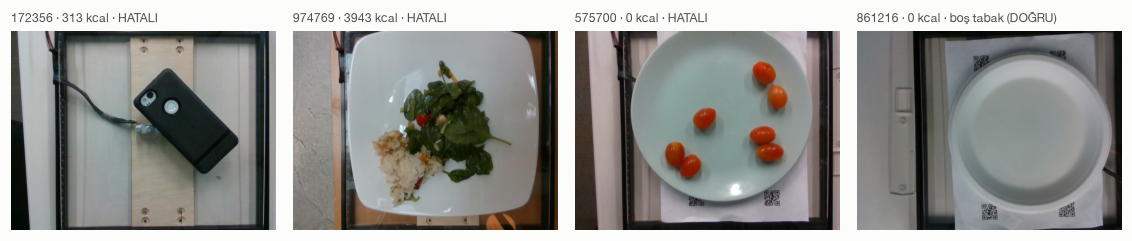

In [5]:
bad = list(BAD_DISHES)
for d in bad:
    r = raw.set_index("dish_id").loc[d]
    print(f"{d} ({r.split}, aykırılık sırası {r.outlier_rank}/{len(raw)}): {BAD_DISHES[d]}")
fig = show_dishes(bad + ["dish_1557861216"],
                  [f"{d[-6:]} · {meta[d]['calories']:.0f} kcal · HATALI" for d in bad] + ["861216 · 0 kcal · boş tabak (DOĞRU)"],
                  ncols=4, name="n5k_hatali_tabaklar")

**Sonuç:** 3 hatalı tabak `BAD_DISHES`'a eklendi (hepsi train'de; eğitimden çıkarılır). Test kümesindeki boş tabak (0 kcal) doğru etiketli,
test kümesine dokunulmaz. Görünüşü normal ama etiketi yanlış tabaklar ancak hata analizinde (Adım 16) yakalanır.

## 3. Kalori dağılımı ve `log1p` kararı

In [6]:
df = raw[~raw.dish_id.isin(BAD_DISHES)].copy()
df["has_fish"] = df.dish_id.map(lambda d: any(n == "fish" for n, _, _ in ingr[d]))
tr = df[df.split == "train"]

desc = df.groupby("split").calories.describe(percentiles=[0.5, 0.9, 0.99]).round(1)
display(desc)
print(f"10 kcal altı tabak: {(df.calories < 10).sum()}  |  0 kcal: {(df.calories == 0).sum()}")
print(f"\nÇarpıklık (train): hatalılar dahil {skew(raw[raw.split == 'train'].calories):.2f} → hariç {skew(tr.calories):.2f}")
for name, x in [("ham", tr.calories), ("log1p", np.log1p(tr.calories)), ("karekök", np.sqrt(tr.calories))]:
    print(f"  {name:<8} çarpıklık {skew(x):+.2f}")

,count,mean,std,min,50%,90%,99%,max
split,,,,,,,,
test,507.0,255.5,212.2,0.0,226.0,519.6,919.0,1050.5
train,2752.0,253.7,209.6,1.8,208.1,538.7,909.1,1324.1


10 kcal altı tabak: 50  |  0 kcal: 1

Çarpıklık (train): hatalılar dahil 2.68 → hariç 1.18
  ham      çarpıklık +1.18
  log1p    çarpıklık -0.80
  karekök  çarpıklık +0.23


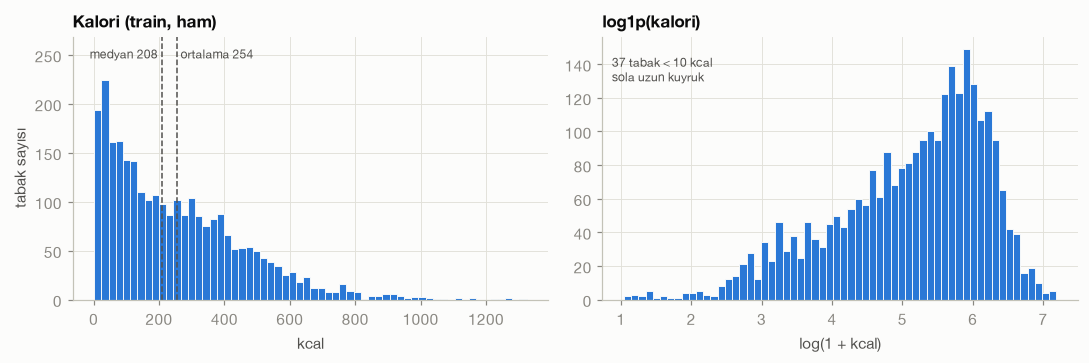

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4))
counts, _, _ = a.hist(tr.calories, bins=60, color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.6)
a.set_ylim(0, counts.max() * 1.2)
for v, lab, ha in [(tr.calories.median(), "medyan", "right"), (tr.calories.mean(), "ortalama", "left")]:
    a.axvline(v, color=INK["secondary"], lw=1, ls="--")
    a.text(v + (12 if ha == "left" else -12), counts.max() * 1.1, f"{lab} {v:.0f}", ha=ha, fontsize=8, color=INK["secondary"])
a.set(title="Kalori (train, ham)", xlabel="kcal", ylabel="tabak sayısı")
b.hist(np.log1p(tr.calories), bins=60, color=SERIES[0], edgecolor="#fcfcfb", linewidth=0.6)
b.set(title="log1p(kalori)", xlabel="log(1 + kcal)")
b.text(0.02, 0.93, f"{(tr.calories < 10).sum()} tabak < 10 kcal\nsola uzun kuyruk", transform=b.transAxes,
       fontsize=8, color=INK["secondary"], va="top")
fig.tight_layout(); savefig(fig, "n5k_kalori_dagilimi");

**`log1p` kararı: baseline'da UYGULANMAYACAK; ablation'da denenecek.**
- Ham dağılımın çarpıklığının büyük kısmı tek bir hatalı tabaktan (3943 kcal) geliyordu; o çıkınca çarpıklık orta düzeyde.
- `log1p` dağılımı ters yöne bozuyor: 10 kcal'in altındaki tabaklar uzun bir sol kuyruk oluşturuyor.
- Değerlendirme metriği **kcal cinsinden MAE**. Log uzayında eğitim, göreli hatayı küçültür ve küçük tabaklara fazla ağırlık verir;
  MAE'yi ise büyük tabaklardaki hatalar belirler. Ham hedef + L1 kaybı doğrudan MAE'yi optimize eder.
- Bu yüzden: **baseline = ham kcal + L1** (`target="raw"`). `log1p` + Huber, ablation tablosundaki satırında denenecek.

## 4. Kalori, kütle ve makrolar

Kalori–kütle korelasyonu: 0.74  |  kcal/g medyanı: 1.10


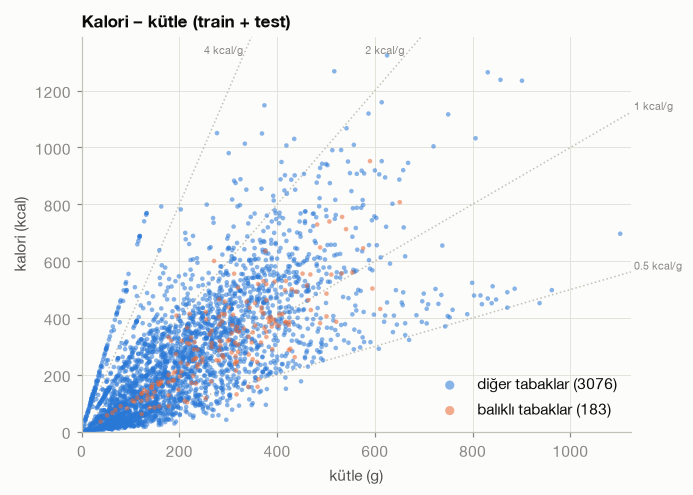

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
xmax, ymax = df.mass.max() * 1.02, df.calories.max() * 1.05
for k in (0.5, 1, 2, 4):
    ax.plot([0, xmax], [0, k * xmax], color=AXIS, lw=1, ls=":", zorder=1)
    y_end = min(k * xmax, ymax * 0.95)
    ax.text(y_end / k, y_end, f" {k:g} kcal/g", fontsize=7, color=INK["muted"], va="bottom", ha="left" if k < 2 else "right")
for fish, color, label in [(False, SERIES[0], "diğer tabaklar"), (True, SERIES[1], "balıklı tabaklar")]:
    s = df[df.has_fish == fish]
    ax.scatter(s.mass, s.calories, s=9, color=color, alpha=0.55, edgecolors="none", label=f"{label} ({len(s)})", zorder=2)
ax.set(xlim=(0, xmax), ylim=(0, ymax), xlabel="kütle (g)", ylabel="kalori (kcal)", title="Kalori – kütle (train + test)")
ax.legend(loc="lower right", markerscale=2)
fig.tight_layout(); savefig(fig, "n5k_kalori_kutle")
print(f"Kalori–kütle korelasyonu: {df.calories.corr(df.mass):.2f}  |  kcal/g medyanı: {(df.calories / df.mass).median():.2f}")

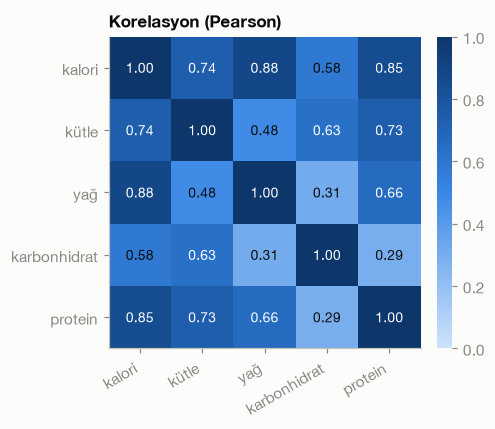

In [9]:
cols = ["calories", "mass", "fat", "carb", "protein"]
labels = ["kalori", "kütle", "yağ", "karbonhidrat", "protein"]
c = df[cols].corr()
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(c, cmap=sequential_cmap(), vmin=0, vmax=1)
ax.set_xticks(range(5), labels, rotation=30, ha="right"); ax.set_yticks(range(5), labels)
ax.grid(False)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if c.iloc[i, j] > 0.6 else INK["primary"])
ax.set_title("Korelasyon (Pearson)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).outline.set_visible(False)
fig.tight_layout(); savefig(fig, "n5k_makro_korelasyon");

Kaloriyle en güçlü ilişki **yağ (0,88)** ve **protein (0,85)**; kütle 0,74. Kütle tek başına yetmiyor: aynı ağırlıkta salata ile
kızartma arasında kat kat fark var (grafikteki kcal/g çizgileri). Bu, çok görevli başlığın (kalori + kütle + makrolar, Adım 12)
ve `kütle × kalori yoğunluğu` fikrinin gerekçesi.

## 5. Atwater kontrolü: kalori ≈ 4·protein + 4·karbonhidrat + 9·yağ

|kalori − Atwater| > 50 kcal: 175 tabak
  bunların 149 tanesi balıklı  (tüm balıklı tabaklar: 183)

Malzeme tablosunda 'fish':


,ingr,cal/g,atwater,fat(g),carb(g),protein(g)
48,fish,0.9,1.906,0.13,0.0,0.184


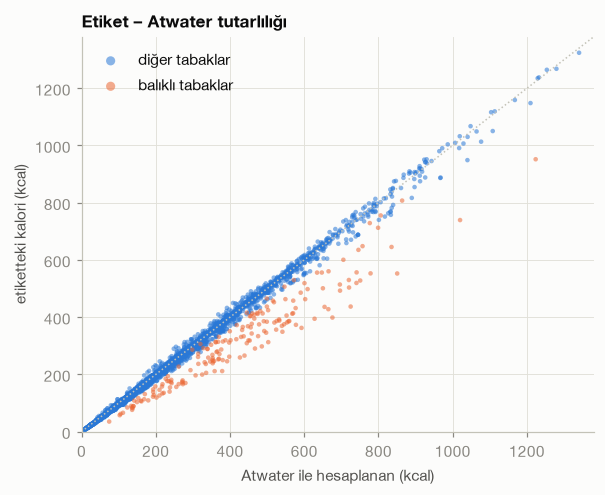

In [10]:
df["atwater"] = 4 * df.protein + 4 * df.carb + 9 * df.fat
df["atwater_gap"] = df.calories - df.atwater
off = df.atwater_gap.abs() > 50
print(f"|kalori − Atwater| > 50 kcal: {off.sum()} tabak")
print(f"  bunların {(off & df.has_fish).sum()} tanesi balıklı  (tüm balıklı tabaklar: {df.has_fish.sum()})")

ing = pd.read_csv(N5K_DIR / "metadata/ingredients_metadata.csv")
ing["atwater"] = 4 * ing["protein(g)"] + 4 * ing["carb(g)"] + 9 * ing["fat(g)"]
print("\nMalzeme tablosunda 'fish':")
display(ing[ing.ingr == "fish"][["ingr", "cal/g", "atwater", "fat(g)", "carb(g)", "protein(g)"]])

fig, ax = plt.subplots(figsize=(5.6, 4.6))
lim = max(df.calories.max(), df.atwater.max()) * 1.03
ax.plot([0, lim], [0, lim], color=AXIS, lw=1, ls=":")
for fish, color, label in [(False, SERIES[0], "diğer tabaklar"), (True, SERIES[1], "balıklı tabaklar")]:
    s = df[df.has_fish == fish]
    ax.scatter(s.atwater, s.calories, s=9, color=color, alpha=0.55, edgecolors="none", label=label)
ax.set(xlim=(0, lim), ylim=(0, lim), xlabel="Atwater ile hesaplanan (kcal)", ylabel="etiketteki kalori (kcal)",
       title="Etiket – Atwater tutarlılığı")
ax.legend(loc="upper left", markerscale=2)
fig.tight_layout(); savefig(fig, "n5k_atwater");

**Sonuç:** Tutarsızlığın kaynağı tek bir malzeme. Nutrition5k'nın malzeme tablosunda **"fish" 0,90 kcal/g** yazıyor; aynı satırdaki
makrolar ise ~1,9 kcal/g'a karşılık geliyor. Balıklı tabakların kalori etiketi muhtemelen **olduğundan düşük**.
(Alkollü içecekler de Atwater'dan sapar, çünkü alkol formülde yok; bunlar hata değil.)

**Karar:** Balıklı tabaklar **çıkarılmıyor**, çünkü resmi etiketler bunlar ve literatür de aynı etiketleri kullanıyor. Ama hata
analizinde (Adım 16) MAE **balıklı / balıksız** ayrı raporlanacak (`read_dish_ingredients()` ile).

## 6. Art arda çekilmiş tabaklar ve sızıntı
Nutrition5k'da tabaklar malzeme malzeme eklenerek art arda çekilmiş. Bu, doğrulama ayrımını ve sonuçların yorumunu etkiliyor.

Cafe 1'deki ardışık tabak çiftleri: 4767; malzemeleri iç içe olan: 2702 (%57)


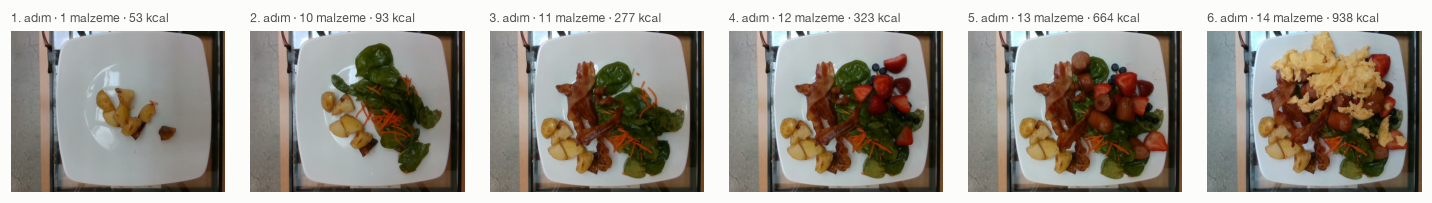

In [11]:
names = {d: frozenset(n for n, _, _ in v) for d, v in ingr.items()}
cafe1 = sorted((d for d in read_split(N5K_DIR / "dish_ids/dish_ids_cafe1.txt") if d in names), key=dish_time)
pairs = list(zip(cafe1, cafe1[1:]))
nested = [a for a, b in pairs if names[a] < names[b] or names[b] < names[a]]
print(f"Cafe 1'deki ardışık tabak çiftleri: {len(pairs)}; malzemeleri iç içe olan: {len(nested)} (%{100 * len(nested) / len(pairs):.0f})")

# Örnek: train'de art arda en az 6 tabaklık, her adımda bir malzeme eklenen bir grup
for g in time_groups(tr.dish_id):
    if len(g) >= 6 and all(names[a] < names[b] for a, b in zip(g[:6], g[1:6])):
        example = g[:6]
        break
fig = show_dishes(example, [f"{i + 1}. adım · {len(names[d])} malzeme · {meta[d]['calories']:.0f} kcal" for i, d in enumerate(example)],
                  ncols=6, name="n5k_art_arda_tabaklar", w=2.2)

In [12]:
usable_train = tr.dish_id.tolist()
tr_ids, val_ids = make_val_split(usable_train)
groups = time_groups(usable_train)
print(f"Zaman grupları (10 dk eşik): {len(groups)} grup, {len(usable_train)} tabak → train {len(tr_ids)} / val {len(val_ids)}")

# Resmi test kümesinde aynı sızıntı var mı?
te = df[df.split == "test"]
tr_times = np.array(sorted(dish_time(d) for d in usable_train))
by_time = {dish_time(d): d for d in usable_train}
near = nested_leak = 0
for d in te.dish_id:
    t = dish_time(d); i = np.searchsorted(tr_times, t)
    neigh = [by_time[tr_times[j]] for j in (i - 1, i) if 0 <= j < len(tr_times) and abs(tr_times[j] - t) <= 600]
    near += bool(neigh)
    nested_leak += any(names[d] <= names[n] or names[n] <= names[d] for n in neigh)
print(f"Resmi test: {len(te)} tabak; 10 dk içinde train komşusu olan {near} (%{100 * near / len(te):.0f}), "
      f"malzemeleri iç içe olan {nested_leak} (%{100 * nested_leak / len(te):.0f})")

Zaman grupları (10 dk eşik): 367 grup, 2752 tabak → train 2472 / val 280
Resmi test: 507 tabak; 10 dk içinde train komşusu olan 416 (%82), malzemeleri iç içe olan 111 (%22)


**Sonuç:**
- Rastgele val ayrımı sızıntı yapardı. Bizim val ayrımımız **zaman gruplu** (`make_val_split`), aynı grup iki kümeye düşmüyor.
- **Resmi test kümesinde de sızıntı var:** test tabaklarının yaklaşık beşte birinin train'de malzeme eklenmiş/çıkarılmış bir
  "kardeşi" var. Literatürdeki tüm sonuçlar aynı resmi ayrımı kullandığı için **karşılaştırma yine adil**, ama mutlak sayılar iyimser.
- **Pratik sonuç:** Bizim val MAE'miz büyük ihtimalle test MAE'sinden **daha kötü** çıkacak. Bu bir hata değil; val daha zor.
  Raporun "sınırlılıklar" bölümüne yazılmalı.

## 7. Kalori aralıkları (Tablo 3)
Sınırlar resmi train'in (hatalılar hariç) üçte birlik dilimleri; bir kez hesaplanıp `src/config.py` → `CALORIE_BIN_EDGES` olarak sabitlendi.

Hesaplanan sınırlar: [116.1 313.7] | config'teki: (116.1, 313.7)


split,test,train
bin,,
düşük (<116),176,917
orta,159,917
yüksek (≥314),172,918


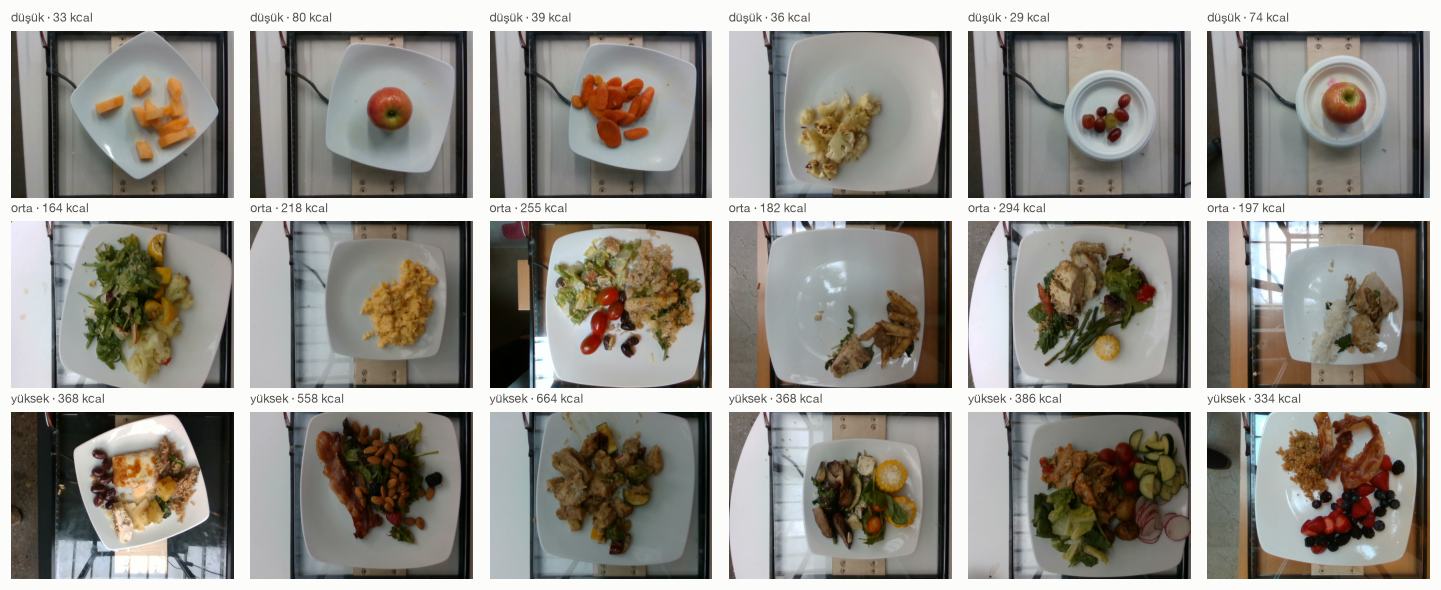

In [13]:
edges = calorie_bins(tr.calories)
print("Hesaplanan sınırlar:", edges.round(1), "| config'teki:", CALORIE_BIN_EDGES)
assert np.allclose(edges, CALORIE_BIN_EDGES, atol=0.1), "Sınırlar değişmiş! Veri veya BAD_DISHES değiştiyse config'i ve devir günlüğünü güncelleyin."
df["bin"] = to_bins(df.calories, CALORIE_BIN_EDGES)
bin_names = {0: f"düşük (<{CALORIE_BIN_EDGES[0]:.0f})", 1: "orta", 2: f"yüksek (≥{CALORIE_BIN_EDGES[1]:.0f})"}
display(pd.crosstab(df.bin.map(bin_names), df.split))

rng = np.random.default_rng(42)
ids, titles = [], []
for b in range(3):
    pick = rng.choice(tr[df.loc[tr.index, "bin"] == b].dish_id.values, 6, replace=False)
    ids += list(pick); titles += [f"{bin_names[b].split(' ')[0]} · {meta[d]['calories']:.0f} kcal" for d in pick]
fig = show_dishes(ids, titles, ncols=6, name="n5k_kalori_araligi_ornekler", w=2.2)

## 8. Veri kartı

In [14]:
val_set = set(val_ids)
df["part"] = np.where(df.split == "test", "test", np.where(df.dish_id.isin(val_set), "val", "train"))
def pm(x): return f"{x.mean():.1f} ± {x.std():.1f}"
card = pd.DataFrame({
    p: {"tabak": len(s), "kalori (kcal)": pm(s.calories), "kalori medyan": f"{s.calories.median():.1f}",
        "kütle (g)": pm(s.mass), "yağ (g)": pm(s.fat), "karbonhidrat (g)": pm(s.carb), "protein (g)": pm(s.protein),
        "balıklı tabak": int(s.has_fish.sum())}
    for p, s in [(p, df[df.part == p]) for p in ("train", "val", "test")]
})
card.to_csv(RESULTS_DIR / "data_card_nutrition5k.csv")
card

,train,val,test
tabak,2472,280,507
kalori (kcal),254.3 ± 211.8,248.2 ± 189.4,255.5 ± 212.2
kalori medyan,208.1,202.4,226.0
kütle (g),215.0 ± 151.6,234.8 ± 172.5,198.5 ± 151.7
yağ (g),12.9 ± 13.6,11.4 ± 12.0,12.8 ± 14.2
karbonhidrat (g),18.9 ± 15.8,20.0 ± 16.1,19.7 ± 17.4
protein (g),18.2 ± 20.4,17.2 ± 17.8,17.5 ± 19.0
balıklı tabak,157,3,23


## 9. Özet: bulgular ve kararlar

| # | Bulgu | Karar / etki |
| --- | --- | --- |
| 1 | 3262 görüntünün hepsi 640×480, okunamayan ve birebir kopya yok | — |
| 2 | 3 hatalı tabak: telefon görüntüsü, "2991 g pirinç" yazım hatası (3943 kcal), domatesli ama "boş tabak" etiketli | `BAD_DISHES`'a eklendi, eğitimden çıkarıldı. Kullanılabilir: **2752 train → 2472 train + 280 val**, **507 test** |
| 3 | Ham kalori sağa çarpık (hatalı tabak çıkınca orta düzeyde); `log1p` dağılımı ters yöne bozuyor | **Baseline: ham kcal + L1.** `log1p` + Huber ablation'da |
| 4 | Kalori yağ (0,88) ve proteinle (0,85) kütleden (0,74) daha ilişkili | Çok görevli başlık (Adım 12) gerekçesi |
| 5 | "fish" malzemesinin kalorisi tabloda düşük girilmiş → balıklı 183 tabağın çoğunda etiket tutarsız | Çıkarılmıyor; hata analizinde balıklı/balıksız MAE ayrı raporlanacak |
| 6 | Ardışık tabakların %57'si malzeme eklenerek çekilmiş; **resmi test tabaklarının ~%22'sinin train'de "kardeşi" var** | Val zaman gruplu; val MAE'nin testten kötü çıkması beklenir; raporda sınırlılık olarak yazılacak |
| 7 | Tablo 3 sınırları: düşük < 116,1 ≤ orta < 313,7 ≤ yüksek | `CALORIE_BIN_EDGES` olarak sabitlendi |

Figürler: `results/figures/n5k_*.png` · Veri kartı: `results/data_card_nutrition5k.csv`